# 実画像で確かめる：圧縮の処理時間と、通信待ち

前回は収集データのschema・値・リプレイを検査しました。今回は、**画像を欠落なく保存する処理**と**古い映像が届く原因**を調べます。

| 課題 | 時間 | 自分で確かめること |
|---|---|---|
| A：depth画像の圧縮 | 準備込み8分 | 実画像の圧縮時間・サイズ・画素の復元 |
| B：通信の混雑 | 8分 | 購読追加・upload・リレー・帯域制限の比較 |
| まとめ | 4分 | 観測値、判断、実機で次に測ること |

ブラウザとGoogleアカウントで、Colabの**CPUランタイム**を使います。GPU・ROS・Docker・実機は不要です。データはノートブック内に同梱しています。追加ダウンロードは不要です。

- **実物**：TUM RGB-D `freiburg1_xyz` のdepth 24枚、対応RGB画像と取得時刻。講師の事故ログではありません。
- **実測**：このランタイムでのPNGエンコード時間と圧縮サイズ。ロボットCPUの性能とは異なります。
- **モデル**：通信帯域・キュー・購読者数・uploadはPythonで条件を変えるシミュレーションです。Wi-Fiを実測しません。
- 必須はTODO-A・B・Cの3か所。詰まったら直下の折りたたみ解答を参照してください。数値が他の人と同じになる必要はありません。
- まとめまでで20分。後半の時計・cgroup・udev・コピー・模擬ログは講義後の発展課題です。

「ファイル → ドライブにコピーを保存」して進めます。

Python 3.13.15 NumPy 2.1.3 Pillow 11.3.0
depth: 24 枚 / uint16 / 640×480 / 5000 units per metre; 0 = invalid


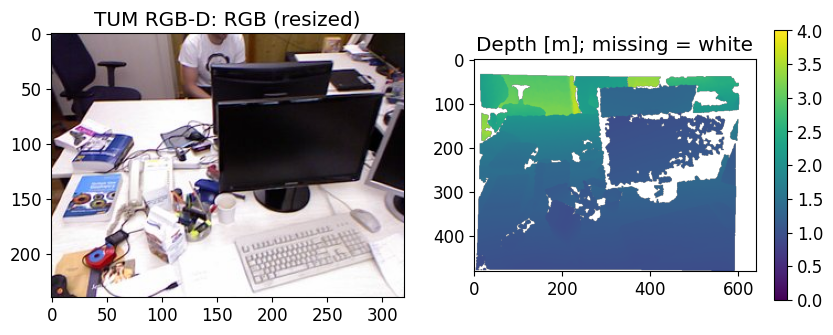

In [1]:
# @title 初期設定：同梱データの展開
# 準備：同梱の実画像を展開する（外部通信なし）
import base64, hashlib, io, json, platform, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import PIL
from PIL import Image
from IPython.display import display

REAL_DIR = Path("real_data")
REAL_ARCHIVE_SHA256 = "f68548ffa7931abff38225ad7801886cfe96505000ddb69db4808ee521125206"
REAL_ARCHIVE_B64 = (
    "..."
    "JwsAAAkkKAAAAA=="
)
payload = base64.b64decode(REAL_ARCHIVE_B64)
assert hashlib.sha256(payload).hexdigest() == REAL_ARCHIVE_SHA256
REAL_DIR.mkdir(exist_ok=True)
with zipfile.ZipFile(io.BytesIO(payload)) as archive:
    for name in archive.namelist():
        assert Path(name).name == name
        (REAL_DIR / name).write_bytes(archive.read(name))
manifest = json.loads((REAL_DIR / "manifest.json").read_text())
records = manifest["frames"]
for r in records:
    for kind in ("depth", "rgb"):
        assert (
            hashlib.sha256((REAL_DIR / r[kind]).read_bytes()).hexdigest()
            == r[kind + "_sha256"]
        )
depth_frames = [
    np.array(Image.open(REAL_DIR / r["depth"]), dtype=np.uint16) for r in records
]
assert len(depth_frames) == 24 and all(a.shape == (480, 640) for a in depth_frames)
print(
    "Python",
    platform.python_version(),
    "NumPy",
    np.__version__,
    "Pillow",
    PIL.__version__,
)
print(
    "depth:",
    len(depth_frames),
    "枚 / uint16 / 640×480 / 5000 units per metre; 0 = invalid",
)
plt.rcParams.update({"font.size": 12, "figure.figsize": (10, 3.5)})
fig, axes = plt.subplots(1, 2)
axes[0].imshow(Image.open(REAL_DIR / records[0]["rgb"]))
axes[0].set_title("TUM RGB-D: RGB (resized)")
view = np.where(depth_frames[0] > 0, depth_frames[0] / 5000, np.nan)
plot = axes[1].imshow(view, vmin=0, vmax=4, cmap="viridis")
axes[1].set_title("Depth [m]; missing = white")
fig.colorbar(plot, ax=axes[1])
plt.show()

## A：小さく保存できても、取得に間に合うか（8分・準備を含む）

講師のROS 1事例では、depthのPNG圧縮がCPUを圧迫して取得Hzが落ち、原因を特定してRVLへ変更しました。ここでは**PNGの圧縮レベル**を変えて、時間と保存量の両方を測ります。RVLとの性能比較ではありません。

depthは各画素が距離を表す16bit整数です。RGB表示用の8bit画像やJPEGに変換すると値が変わるため、PNGの復元後に**全画素の完全一致**を確認します。

まず「レベルを上げるとサイズと時間はどう変わるか」を予想してください。用意した計測関数は24枚×3回を順序を混ぜて測り、medianとp95を出します。ディスクI/Oとデコードは計測時間に含めません。

In [2]:
"""Runtime helpers embedded into both notebooks; no network or hardware access."""

import io
import time
import numpy as np
import pandas as pd
from PIL import Image


def encode_depth(array, level):
    if array.dtype != np.uint16 or array.ndim != 2:
        raise ValueError("Depth must be a uint16 image")
    buffer = io.BytesIO()
    Image.fromarray(array).save(buffer, format="PNG", compress_level=level)
    return buffer.getvalue()


def benchmark_depth(frames, levels=(1, 6, 9), repeats=3):
    # Warm up each level. Exclude disk I/O; include in-memory PNG encoding.
    for level in levels:
        encode_depth(frames[0], level)
    jobs = [
        (level, i, repeat)
        for level in levels
        for i in range(len(frames))
        for repeat in range(repeats)
    ]
    np.random.default_rng(7).shuffle(jobs)
    rows = []
    for level, i, repeat in jobs:
        start = time.perf_counter()
        payload = encode_depth(frames[i], level)
        elapsed = (time.perf_counter() - start) * 1000
        # Decode and correctness check are intentionally outside timed region.
        decoded = np.array(Image.open(io.BytesIO(payload)), dtype=np.uint16)
        assert np.array_equal(decoded, frames[i]), "Depth changed after round trip"
        rows.append(
            dict(
                level=level,
                frame=i,
                repeat=repeat,
                encode_ms=elapsed,
                bytes=len(payload),
            )
        )
    return pd.DataFrame(rows)


def simulate_network(
    frame_sizes,
    copies=1,
    upload_rate=0,
    capacity=None,
    fps=15,
    duration=6,
    upload_bytes=None,
):
    """One work-conserving FIFO link; no loss, retries, decode, or Wi-Fi MAC.

    Every upload scenario sends the SAME total payload, paced by upload_rate.
    Results include transfers beyond the observation horizon (not discarded).
    copies models robot-to-PC unicast duplication; relay is on the PC side.
    """
    sizes = np.asarray(frame_sizes, dtype=int)
    assert len(sizes) and np.all(sizes > 0) and copies >= 1
    demand = sizes.mean() * fps
    capacity = float(capacity or 1.4 * demand)  # bytes/s, pedagogical link
    assert capacity > 0 and upload_rate >= 0
    jobs = []
    n = int(duration * fps)
    for i in range(n):
        for copy in range(copies):
            jobs.append(
                dict(
                    release=i / fps,
                    size=int(sizes[i % len(sizes)]),
                    kind="video" if copy == 0 else "debug",
                    frame=i,
                )
            )
    total_upload = (
        int(upload_bytes if upload_bytes is not None else demand * duration * 0.8)
        if upload_rate
        else 0
    )
    chunk = 4096  # packet-like chunks, avoids modeling one giant indivisible upload
    for offset in range(0, total_upload, chunk):
        jobs.append(
            dict(
                release=offset / upload_rate,
                size=min(chunk, total_upload - offset),
                kind="upload",
                frame=-1,
            )
        )
    jobs.sort(key=lambda r: r["release"])
    free = 0.0
    for job in jobs:
        job["start"] = max(free, job["release"])
        job["finish"] = job["start"] + job["size"] / capacity
        job["latency_ms"] = (job["finish"] - job["release"]) * 1000
        free = job["finish"]
    df = pd.DataFrame(jobs)
    video = df[df.kind == "video"].copy()
    uploaded = sum(
        max(0, min(r["size"], (duration - r["start"]) * capacity))
        for r in jobs
        if r["kind"] == "upload"
    )
    summary = dict(
        p95_video_ms=float(video.latency_ms.quantile(0.95)),
        max_video_ms=float(video.latency_ms.max()),
        video_delivered=int((video.finish <= duration).sum()),
        upload_total_bytes=total_upload,
        upload_remaining_bytes=total_upload - uploaded,
        upload_finish_s=float(df.loc[df.kind == "upload", "finish"].max())
        if total_upload
        else 0,
    )
    grid = np.linspace(0, duration, 301)
    queue = np.array(
        [
            sum(
                max(0, min(r["size"], (r["finish"] - t) * capacity))
                for r in jobs
                if r["release"] <= t < r["finish"]
            )
            for t in grid
        ]
    )
    # Age of most recently delivered image; no frame exists before first arrival.
    age = []
    for t in grid:
        seen = video[video.finish <= t]
        age.append((t - seen.release.iloc[-1]) * 1000 if len(seen) else np.nan)
    return dict(
        jobs=df,
        video=video,
        summary=summary,
        time=grid,
        queue_bytes=queue,
        age_ms=np.array(age),
        capacity=capacity,
    )

非圧縮1枚: 614400 bytes


,median_ms,p95_ms,mean_bytes,raw_ratio,ms_budget_at_30fps
level,,,,,
1,16.174,28.411,116426.750,0.189,33.333
6,49.535,69.152,89829.500,0.146,33.333
9,572.433,843.734,84158.375,0.137,33.333


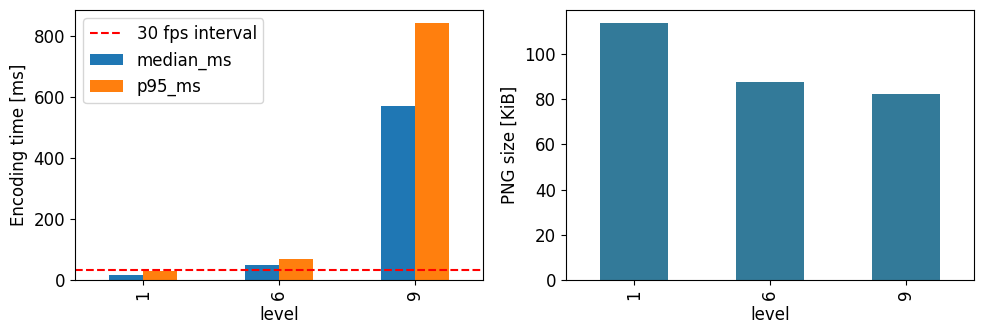

self-check: 全測定でdepth画素が完全復元できました


In [3]:
# 【TODO-A】PNGの3つの圧縮レベルを比較する
levels = [1, 6, 9]
measurements = benchmark_depth(depth_frames, levels=levels, repeats=3)
compression = measurements.groupby("level").agg(
    median_ms=("encode_ms", "median"),
    p95_ms=("encode_ms", lambda x: x.quantile(0.95)),
    mean_bytes=("bytes", "mean"),
)
compression["raw_ratio"] = compression.mean_bytes / depth_frames[0].nbytes
compression["ms_budget_at_30fps"] = 1000 / 30
print("非圧縮1枚:", depth_frames[0].nbytes, "bytes")
display(compression.round(3))
fig, axes = plt.subplots(1, 2)
compression[["median_ms", "p95_ms"]].plot.bar(ax=axes[0])
axes[0].axhline(1000 / 30, color="red", linestyle="--", label="30 fps interval")
axes[0].legend()
axes[0].set_ylabel("Encoding time [ms]")
compression.mean_bytes.div(1024).plot.bar(ax=axes[1], color="#337a99")
axes[1].set_ylabel("PNG size [KiB]")
plt.tight_layout()
plt.show()
assert len(measurements) == 24 * 3 * len(levels)
assert (measurements.encode_ms > 0).all()
print("self-check: 全測定でdepth画素が完全復元できました")

**結果を読む**：サイズが小さい設定と時間が短い設定は同じでしたか。30fpsの33.3msは仮の1フレーム予算です。圧縮だけがこの値以下でも、カメラ取得・ROS処理・保存I/Oを含む30Hzを保証しません。p95はこの短い測定の標本値です。

実機で次に取る情報を1つ挙げてください（例：圧縮プロセスのCPU使用率、画像ヘッダ時刻の間隔、保存待ちキュー）。

## B：届いているのに、映像が古い（8分）

RGBは実画像ですが、以下の通信時刻は**モデルで生成**します。縮小JPEGの実際のバイト数を使い、15fps・6秒間の映像送信を考えます。24枚を繰り返すため、時刻は元データの時刻とは異なります。

```text
対策前：ロボット ── Wi-Fi相当の共有回線 ── テレオペPC・デバッグPC
                    映像を2部 + upload
対策後：ロボット ── 同じ共有回線 ── 外部PC上のリレー → 複数の表示
                    映像を1部 + 制限したupload
```

回線容量を「映像1本の平均需要×1.4」に設定し、競合が見える条件を作ります。実Wi-Fiの公称速度ではありません。共有回線は先着順・損失なし・容量一定とし、無線の再送・ROS実装・デコード・下流LAN負荷は省略します。

uploadは同じ総バイト数を送ります。制限すると送信終了が遅くなるため、6秒時点の未転送量も比較します。

In [4]:
# 【TODO-B】1本の映像の需要を bytes/s で計算する
frame_sizes = [(REAL_DIR / r["rgb"]).stat().st_size for r in records]
fps, duration = 15, 6
demand = np.mean(frame_sizes) * fps
capacity = 1.4 * demand
upload_total = int(demand * duration * 0.8)
assert np.isclose(demand, np.mean(frame_sizes) * fps), (
    "平均bytes/frame × frames/s を確認"
)
print(
    f"映像1本 {demand * 8 / 1e6:.2f} Mbit/s、モデル回線 {capacity * 8 / 1e6:.2f} Mbit/s"
)

映像1本 2.36 Mbit/s、モデル回線 3.31 Mbit/s


,p95_video_ms,max_video_ms,video_delivered,upload_total_bytes,upload_remaining_bytes,upload_finish_s
teleop only,51.30,53.16,90.0,0.0,0.0,0.00
+ debug,2452.62,2580.62,63.0,0.0,0.0,0.00
+ debug + upload,5678.72,5978.60,45.0,1417575.0,704871.0,11.99
relay + upload,1658.74,1744.94,70.0,1417575.0,311655.0,7.71
relay + limited upload,54.37,56.69,90.0,1417575.0,1061223.0,23.99


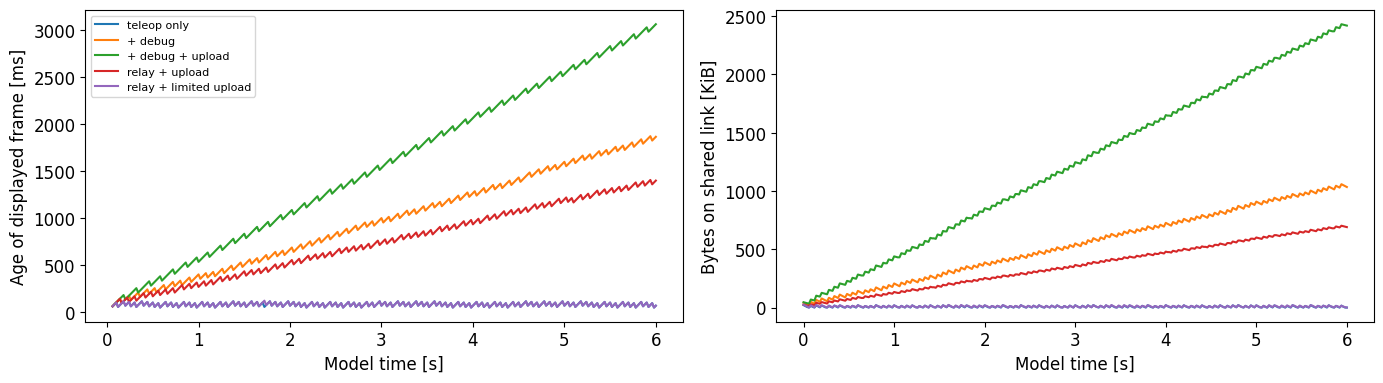

self-check: 映像の待ちを減らす一方、upload完了が遅くなることを確認


In [5]:
# 【TODO-C】リレー後の映像の部数とuploadの速度を設定する
relay_copies = 1
limited_upload_rate = demand * 0.2
scenarios = {
    "teleop only": (1, 0),
    "+ debug": (2, 0),
    "+ debug + upload": (2, demand * 0.8),
    "relay + upload": (relay_copies, demand * 0.8),
    "relay + limited upload": (relay_copies, limited_upload_rate),
}
runs = {
    name: simulate_network(
        frame_sizes,
        copies=copies,
        upload_rate=rate,
        capacity=capacity,
        fps=fps,
        duration=duration,
        upload_bytes=upload_total,
    )
    for name, (copies, rate) in scenarios.items()
}
summary = pd.DataFrame({name: run["summary"] for name, run in runs.items()}).T
display(summary.round(2))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, run in runs.items():
    axes[0].plot(run["time"], run["age_ms"], label=name)
    axes[1].plot(run["time"], run["queue_bytes"] / 1024, label=name)
axes[0].set(xlabel="Model time [s]", ylabel="Age of displayed frame [ms]")
axes[1].set(xlabel="Model time [s]", ylabel="Bytes on shared link [KiB]")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
assert relay_copies == 1 and np.isclose(limited_upload_rate, demand * 0.2)
assert (
    summary.loc["relay + limited upload", "p95_video_ms"]
    < summary.loc["+ debug + upload", "p95_video_ms"]
)
assert (
    summary.loc["relay + limited upload", "upload_finish_s"]
    > summary.loc["relay + upload", "upload_finish_s"]
)
print("self-check: 映像の待ちを減らす一方、upload完了が遅くなることを確認")

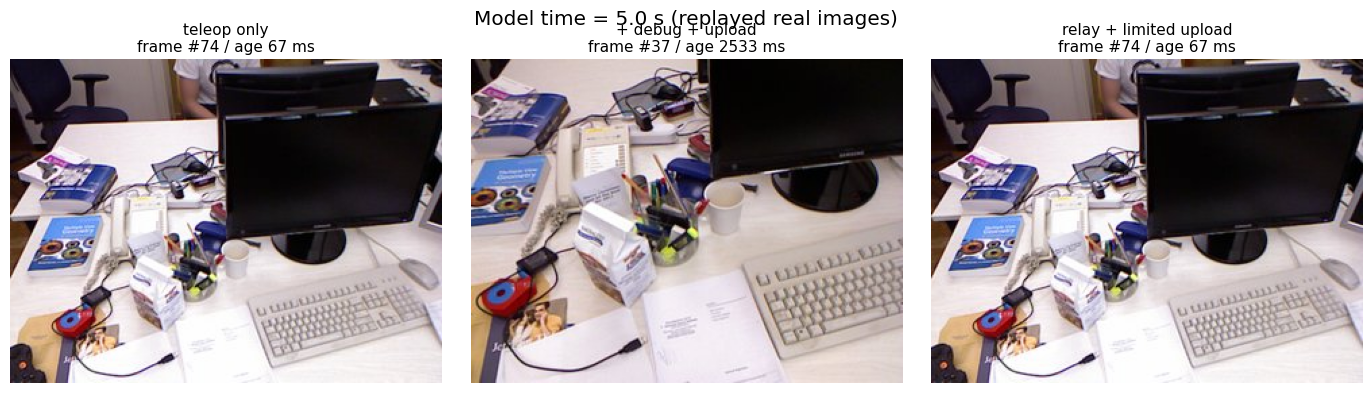

In [6]:
# 同じモデル時刻に表示されている画像を見る。tを変えて再実行できます。
t = 5.0
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(
    axes, ["teleop only", "+ debug + upload", "relay + limited upload"]
):
    video = runs[name]["video"]
    seen = video[video.finish <= t]
    if len(seen):
        last = seen.iloc[-1]
        image = Image.open(REAL_DIR / records[int(last.frame) % len(records)]["rgb"])
        ax.imshow(image)
        ax.set_title(
            f"{name}\nframe #{int(last.frame)} / age {(t - last.release) * 1000:.0f} ms",
            fontsize=11,
        )
    else:
        ax.set_title(name + "\nNo delivered image")
    ax.axis("off")
plt.suptitle(f"Model time = {t:.1f} s (replayed real images)")
plt.tight_layout()
plt.show()

## まとめ（4分）— 必須はここまで

手元に次の3点を書いてください。提出は不要です。

1. **圧縮**：比較した設定、時間とサイズ、画素一致。実機で変える前に何を追加計測するか。
2. **通信**：購読者追加・uploadでフレームの古さがどう変わったか。リレーと帯域制限の代償は何か。
3. **収集前の検査**：第2回のvalidationに加える項目を一つ選び、閾値を決めるために何を測るか。

**解答の考え方**：圧縮率だけで判断せず、フレーム予算とCPU処理を併記します。外部PC側のリレーは共有回線での重複転送を減らします。upload制限は映像の待ちを減らしますが、保存完了を遅らせ、ロボット内の保管量を増やします。モデルの結果だけから実Wi-Fiの必要速度や安全な閾値は断定できません。

## 発展A：実際の取得時刻に、時計ずれを注入する

元データのRGB/depthタイムスタンプは変更していません。そこへ**人工的な+120ms**を加え、対応するフレーム同士の時刻差を観察します。これはchronyやTFの障害記録ではなく、時計のずれと輸送遅延を区別する練習です。

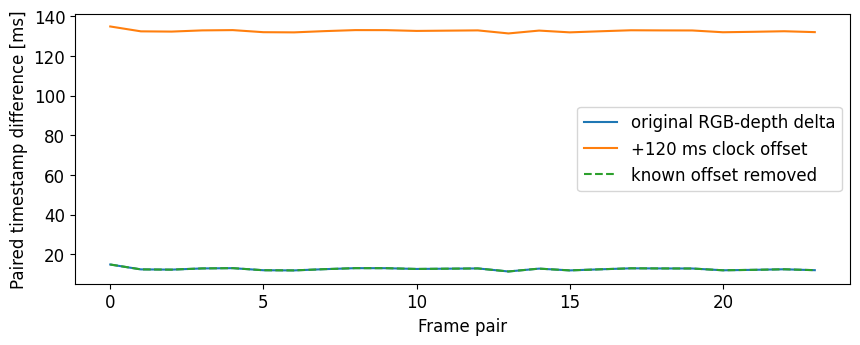

注入した定数を除けました。元のセンサ取得時刻差は残っています。


In [7]:
paired_delta_ms = np.array([(r["rgb_time"] - r["depth_time"]) * 1000 for r in records])
injected_offset_ms = 120
shifted_delta_ms = paired_delta_ms + injected_offset_ms
corrected_delta_ms = shifted_delta_ms - injected_offset_ms
plt.plot(paired_delta_ms, label="original RGB-depth delta")
plt.plot(shifted_delta_ms, label="+120 ms clock offset")
plt.plot(corrected_delta_ms, "--", label="known offset removed")
plt.ylabel("Paired timestamp difference [ms]")
plt.xlabel("Frame pair")
plt.legend()
plt.show()
assert np.allclose(corrected_delta_ms, paired_delta_ms)
print("注入した定数を除けました。元のセンサ取得時刻差は残っています。")

## 発展B：コピー・模擬ログ・cgroup・udev

ここからは時間外の追加課題です。以下のStep番号は発展内の番号です。CPU・メモリ上限は読めない環境もあり、その場合は未確認と記録します。ログ7ファイルは合成データです。

## 発展 Step 0：配布物と環境（S94）

以下の追加ログ7ファイルはすべて現場のログを模した **合成データ** です（不良の真値は講師キットのみ）。
データはこのノートブックに同梱しています。次のセルを実行すると `data/` に展開されるため、別ファイルのアップロードや配布URLの設定は不要です。

| ファイル | 内容 | 使う Step |
|---|---|---|
| `chrony_pc1.csv`, `chrony_pc2.csv` | 2 台の PC の `chronyc tracking` 相当の時系列（10 s 間隔、2 時間） | 2 |
| `topic_stats.csv` | トピックごとの構成と、1 秒ごとの実測 hz / 帯域（有線 → Wi‑Fi） | 2 |
| `udevadm_info_ttyUSB0.txt` | `udevadm info -a -n /dev/ttyUSB0` の出力 | 4 |
| `pyspy_top.txt` | `py-spy top` の出力 | 5 |
| `nvidia_dmon.csv` | `nvidia-smi dmon` 相当の GPU 時系列 | 5 |
| `train_steps.csv` | 学習 step ごとの時間の内訳 | 5 |

追加インストールは不要です（numpy, pandas, matplotlib は Colab に入っています）。

In [8]:
# @title 初期設定：同梱データの展開
# セル 0-1: 同梱した配布データを data/ に展開する
import base64
import hashlib
import io
import os
import re
import time
import zipfile
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("data")
DATA_FILES = [
    "chrony_pc1.csv",
    "chrony_pc2.csv",
    "topic_stats.csv",
    "pyspy_top.txt",
    "nvidia_dmon.csv",
    "train_steps.csv",
    "udevadm_info_ttyUSB0.txt",
]

DATA_ARCHIVE_SHA256 = "c8fc08d99addabcaea99f43fe3a26ab7b19bf7f4df4030c3d20f4bd8f9c316fa"
DATA_ARCHIVE_B64 = (
    "..."
)
archive_bytes = base64.b64decode(DATA_ARCHIVE_B64)
assert hashlib.sha256(archive_bytes).hexdigest() == DATA_ARCHIVE_SHA256, (
    "同梱データが壊れています。配布ノートブックを開き直してください"
)
DATA_DIR.mkdir(exist_ok=True)
with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
    assert sorted(archive.namelist()) == sorted(DATA_FILES)
    for filename in DATA_FILES:
        (DATA_DIR / filename).write_bytes(archive.read(filename))
missing = [f for f in DATA_FILES if not (DATA_DIR / f).exists()]
assert not missing, f"足りないファイル: {missing}"
print("data/ OK:", ", ".join(DATA_FILES))

# 図の見た目（画面共有向けに大きめ。ラベルは英語にしてフォント問題を避ける）
mpl.rcParams.update(
    {
        "font.size": 14,
        "axes.labelsize": 14,
        "axes.titlesize": 15,
        "legend.fontsize": 12,
        "figure.figsize": (9, 3.6),
        "axes.grid": True,
        "grid.alpha": 0.3,
    }
)
ACCENT, GRAY = "#4C72B0", "0.45"


def fp(value: object) -> str:
    """self-check 用: 値の SHA-256 先頭 12 桁（答えの数値をノートに書かないため）"""
    return hashlib.sha256(str(value).encode()).hexdigest()[:12]

data/ OK: chrony_pc1.csv, chrony_pc2.csv, topic_stats.csv, pyspy_top.txt, nvidia_dmon.csv, train_steps.csv, udevadm_info_ttyUSB0.txt


## 発展 Step 1：メモリ（発展4分）— S12, S17, S18

- 発展1-1：画像1枚の copy と view を計測。コピー時間は環境によって変わります（S17）
- 発展1-2：画像 1000 枚を「コピーして渡す」と「view で渡す」で、時間と `tracemalloc` のピークを比べる（S17）
- 発展1-3：同じファイルを 2 回読んで、2 回目が速い理由 = **ページキャッシュ** を確かめる（S18）

In [9]:
# セル 1-1【TODO-1】: 画像 1 枚の copy と view の時間を比べる
img = np.random.default_rng(0).integers(0, 256, size=(720, 1280, 3), dtype=np.uint8)
print(f"画像 1 枚 = {img.nbytes / 1e6:.2f} MB, dtype={img.dtype}, shape={img.shape}")

# ---- TODO-1 ここから (3 行): %timeit -o で「copy」と「view」の時間を測り、比 ratio を求める
#   ヒント: t = %timeit -o -q 式   とすると t.average に平均秒が入る
#   copy の例: img.copy()      view の例: img[::2, ::2]（スライスはコピーしない）
t_copy = %timeit -o -q img.copy()
t_view = %timeit -o -q img[::2, ::2]
ratio = t_copy.average / t_view.average
# ---- TODO-1 ここまで

print(
    f"copy: {t_copy.average * 1e3:.3f} ms/枚,   view: {t_view.average * 1e6:.2f} us/枚,   ratio: {ratio:,.0f} 倍"
)
per_s = t_copy.average * 30 * 2 * 4  # 30 Hz × 2 台 × 4 回コピー（S17）
print(
    f"30 Hz × 2 台で 4 回コピーすると、1 秒あたり {per_s * 1e3:.0f} ms = 1 コアの {per_s:.0%}"
)

画像 1 枚 = 2.76 MB, dtype=uint8, shape=(720, 1280, 3)
copy: 0.238 ms/枚,   view: 0.40 us/枚,   ratio: 600 倍
30 Hz × 2 台で 4 回コピーすると、1 秒あたり 57 ms = 1 コアの 6%


In [10]:
# セル 1-2【TODO-2】: 1000 枚を「コピーして渡す」vs「view で渡す」。時間と tracemalloc のピークを比べる
import tracemalloc
from collections import deque
from collections.abc import Callable

N_FRAMES, QUEUE_LEN = (
    1000,
    50,
)  # 受信側の queue に 50 枚ぶん溜まる想定（subscriber queue のイメージ）


def run_pipeline(make_frame: Callable[[int], np.ndarray]) -> tuple[float, float]:
    """make_frame(i) が返す frame を長さ QUEUE_LEN の queue に流す。(所要秒, ピーク MB) を返す"""
    queue: deque[np.ndarray] = deque(maxlen=QUEUE_LEN)
    tracemalloc.start()
    t0 = time.perf_counter()
    for i in range(N_FRAMES):
        queue.append(make_frame(i))
    elapsed = time.perf_counter() - t0
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return elapsed, peak / 1e6


# ---- TODO-2 ここから (各 1 行, 計 2 行): 「コピーして渡す」と「view で渡す」を書く
#   コピー: img のコピーを返す      view: img のスライス（例: 先頭 i % 10 行を飛ばす）を返す
def make_copy(i: int) -> np.ndarray:
    return img.copy()


def make_view(i: int) -> np.ndarray:
    return img[i % 10 :]


# ---- TODO-2 ここまで

t_c, peak_c = run_pipeline(make_copy)
t_v, peak_v = run_pipeline(make_view)
print(f"copy: {t_c * 1e3:7.1f} ms / {N_FRAMES} 枚,  ピーク {peak_c:7.1f} MB")
print(f"view: {t_v * 1e3:7.1f} ms / {N_FRAMES} 枚,  ピーク {peak_v:7.1f} MB")

copy:   555.5 ms / 1000 枚,  ピーク   141.0 MB
view:     1.7 ms / 1000 枚,  ピーク     0.0 MB


In [11]:
# セル 1-4【self-check】Step 1 必須
assert ratio >= 10, f"copy/view の差が小さい場合は再計測してください（{ratio:.1f} 倍）"
assert t_c > 10 * t_v, "1000 枚のコピーと view の時間を再確認してください"
assert peak_c > 10 * peak_v, "コピーと view のピークメモリを再確認してください"
assert peak_c > QUEUE_LEN * img.nbytes / 1e6 * 0.9, (
    "キューに保持する画像の量を確認してください"
)
print(
    f"Step 1 必須 self-check: OK (copy {t_copy.average * 1e3:.3f} ms, copy/view {ratio:,.0f} 倍)"
)

Step 1 必須 self-check: OK (copy 0.238 ms, copy/view 600 倍)


In [12]:
# セル 1-3【TODO-3】（発展）: 同じファイルを 2 回読む。2 回目が速い理由 = ページキャッシュ（S18）
PROBE = Path("pagecache_probe.bin")
SIZE_MB = 256

with open(PROBE, "wb") as f:  # 書く → fsync でディスクへ流す（dirty page を吐き出す）
    f.write(np.random.default_rng(1).bytes(SIZE_MB * 2**20))
    f.flush()
    os.fsync(f.fileno())


def drop_from_page_cache(path: Path) -> None:
    """このファイルのページをキャッシュから追い出す（root 不要の posix_fadvise）"""
    fd = os.open(path, os.O_RDONLY)
    try:
        os.fsync(fd)
        if hasattr(os, "posix_fadvise"):
            os.posix_fadvise(fd, 0, 0, os.POSIX_FADV_DONTNEED)
        else:
            print("このOSではページキャッシュの解放要求は未実施です。")
    finally:
        os.close(fd)


def cached_mb() -> float:
    """/proc/meminfo の Cached（free -h の buff/cache に相当）を MB で返す"""
    if not Path("/proc/meminfo").exists():
        return float("nan")
    for line in Path("/proc/meminfo").read_text().splitlines():
        if line.startswith("Cached:"):
            return int(line.split()[1]) / 1024
    return float("nan")


def read_all(path: Path) -> float:
    """ファイルを 8 MB ずつ最後まで読み、かかった秒数を返す"""
    # ---- TODO-3 ここから (4〜5 行): perf_counter で計り、f.read(8 * 2**20) が空になるまで読む
    t0 = time.perf_counter()
    with open(path, "rb") as f:
        while f.read(8 * 2**20):
            pass
    return time.perf_counter() - t0
    # ---- TODO-3 ここまで


drop_from_page_cache(PROBE)
c0 = cached_mb()
t_first = read_all(PROBE)
c1 = cached_mb()
t_second = read_all(PROBE)
PROBE.unlink()
print(
    f"1 回目 {t_first * 1e3:7.1f} ms ({SIZE_MB / 1e3 / t_first:5.2f} GB/s)   2 回目 {t_second * 1e3:7.1f} ms ({SIZE_MB / 1e3 / t_second:5.2f} GB/s)"
)
print(
    f"Cached: {c0:.0f} MB → {c1:.0f} MB（1 回目の読み出しで約 +{c1 - c0:.0f} MB がページキャッシュに載った）"
)

1 回目   159.6 ms ( 1.60 GB/s)   2 回目    77.6 ms ( 3.30 GB/s)
Cached: 3280 MB → 3536 MB（1 回目の読み出しで約 +256 MB がページキャッシュに載った）


In [13]:
# セル 1-5【self-check】Step 1 発展
assert t_first > 0 and t_second > 0
print(f"ページキャッシュの観測: 1回目/2回目 = {t_first / t_second:.2f}")
print("2回目が速くならない場合も、キャッシュ状態や実行環境を確認して記録してください。")

ページキャッシュの観測: 1回目/2回目 = 2.06
2回目が速くならない場合も、キャッシュ状態や実行環境を確認して記録してください。


## 発展 Step 2：通信（発展4分）— S33, S36, S37, S43, S47

- 発展2-1：2 台の PC の `chronyc tracking` 相当のログを見る（S37：System time / Last offset / RMS offset / Frequency / Root delay / Root dispersion）
- 発展2-2：offset の時系列に **直線を当てはめてドリフト（ppm）を推定** し、同期が外れた時刻を特定する（S33：20 ppm なら 1 日で 1.7 秒）
- 発展2-3：カメラ構成から **帯域を試算する関数** を書き、実測と比べる（S43）
- 発展2-4：Wi‑Fi を飽和させたトピックを 1 つ特定する（S44, S47）

> 注：pc2 は「補正が効いていない時計」を模した合成データです。実機の chrony なら同期中の System time は小さく保たれます。`frequency_ppm` 列は chrony が推定した「時計の速さ」で、同期が切れた後は更新されません。

In [14]:
# セル 2-3【TODO-5】: 帯域の試算関数（S43）。topic_stats.csv の実測と比べる
ts = pd.read_csv(DATA_DIR / "topic_stats.csv")


def estimate_bw_mbps(
    width: int,
    height: int,
    bytes_per_px: int,
    fps: float,
    compression_ratio: float = 1.0,
) -> float:
    """非圧縮 1 フレーム = width × height × bytes_per_px バイト。fps 枚/秒を圧縮率で割り、bit/s → Mbps に直す"""
    # ---- TODO-5 ここから (2〜3 行)
    bytes_per_frame = width * height * bytes_per_px / compression_ratio
    return bytes_per_frame * fps * 8 / 1e6
    # ---- TODO-5 ここまで


print(
    f"S43 の例: 1280×720×3 B × 30 fps = {estimate_bw_mbps(1280, 720, 3, 30):.0f} Mbps（非圧縮）, JPEG 1/15 なら {estimate_bw_mbps(1280, 720, 3, 30, 15):.0f} Mbps"
)

# 構成表（トピックごとに 1 行）と、試算 vs 実測（有線区間 / Wi-Fi 区間の平均）
cfg = ts.groupby("topic").first()[
    ["width", "height", "bytes_per_px", "fps_nominal", "compression_ratio", "msg_bytes"]
]
cfg["estimate_mbps"] = [
    estimate_bw_mbps(
        r.width, r.height, r.bytes_per_px, r.fps_nominal, r.compression_ratio
    )
    if r.width > 0
    else r.msg_bytes * r.fps_nominal * 8 / 1e6  # 画像以外はメッセージサイズ × 周波数
    for r in cfg.itertuples()
]
meas = ts.pivot_table(
    index="topic",
    columns="link",
    values=["bw_mbps_measured", "hz_measured"],
    aggfunc="mean",
)
table = cfg[["fps_nominal", "msg_bytes", "estimate_mbps"]].copy()
table["wired_mbps"] = meas[("bw_mbps_measured", "wired")]
table["wifi_mbps"] = meas[("bw_mbps_measured", "wifi")]
table["wired_hz"] = meas[("hz_measured", "wired")]
table["wifi_hz"] = meas[("hz_measured", "wifi")]
print(table.sort_values("estimate_mbps", ascending=False).round(2).to_string())
print(
    f"\n合計の試算: {cfg.estimate_mbps.sum():.0f} Mbps（有線 1 Gbps には収まる。Wi-Fi の実効 100〜200 Mbps には収まらない）"
)

S43 の例: 1280×720×3 B × 30 fps = 664 Mbps（非圧縮）, JPEG 1/15 なら 44 Mbps
                                fps_nominal  msg_bytes  estimate_mbps  wired_mbps  wifi_mbps  wired_hz  wifi_hz
topic                                                                                                          
/cam_head/depth/image_raw                30     814080         195.38      195.23      59.18     29.98     9.09
/cam_head/image_raw                      15     305280          36.63       36.71      13.17     15.03     5.39
/cam_wrist/image_raw                     15     305280          36.63       36.65      13.33     15.02     5.45
/cam_head/image_raw/compressed           15      25440           3.05        3.05       1.22     14.98     6.00
/joint_states                           200        560           0.90        0.90       0.36    199.93    80.01
/tf                                     100        840           0.67        0.67       0.27     99.81    40.05
/wrench                             

Wi-Fi 区間で帯域を食っているトピック: /cam_head/depth/image_raw


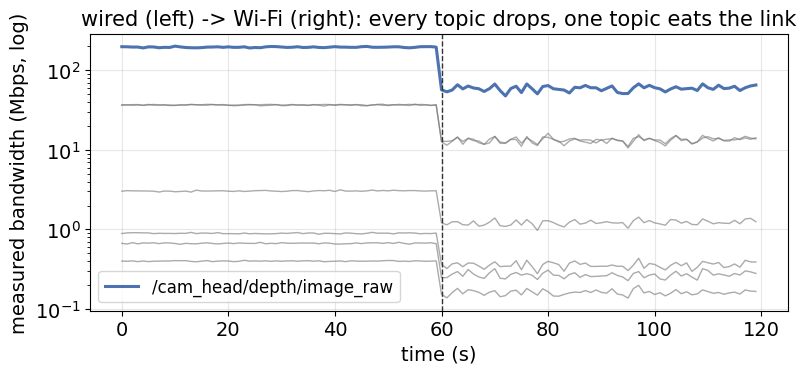

In [15]:
# セル 2-4【TODO-6】: Wi-Fi を飽和させたトピックを 1 つ特定する
# ---- TODO-6 ここから (2 行): Wi-Fi 区間 (link == "wifi") で、平均帯域が最大のトピック名を culprit に
wifi = ts[ts.link == "wifi"]
culprit = wifi.groupby("topic").bw_mbps_measured.mean().idxmax()
# ---- TODO-6 ここまで
print("Wi-Fi 区間で帯域を食っているトピック:", culprit)

fig, ax = plt.subplots()
for topic, g in ts.groupby("topic"):
    hit = topic == culprit
    ax.plot(
        g.t_s,
        g.bw_mbps_measured,
        lw=2.2 if hit else 1.0,
        color=ACCENT if hit else GRAY,
        alpha=1.0 if hit else 0.6,
        label=topic if hit else None,
    )
ax.axvline(ts.loc[ts.link == "wifi", "t_s"].min(), color="0.2", ls="--", lw=1)
ax.set_yscale("log")
ax.set_xlabel("time (s)")
ax.set_ylabel("measured bandwidth (Mbps, log)")
ax.set_title(
    "wired (left) -> Wi-Fi (right): every topic drops, one topic eats the link"
)
ax.legend(loc="lower left")
plt.show()

In [16]:
# セル 2-5【self-check】Step 2 必須
assert abs(estimate_bw_mbps(1280, 720, 3, 30) - 663.55) < 1.0, (
    "S43 の例と一致しません（1280×720×3×30×8 / 1e6）"
)
img_topics = table[cfg.width > 0]
rel_err = (
    (img_topics.estimate_mbps - img_topics.wired_mbps) / img_topics.estimate_mbps
).abs()
assert (rel_err < 0.1).all(), (
    f"有線区間の実測は試算と ±10% で一致するはず:\n{rel_err.round(3)}"
)
assert fp(culprit) == "b422724961d2", f"飽和トピックが違います: {culprit}"
print(f"Step 2 必須 self-check: OK (最大帯域のトピック = {culprit})")

Step 2 必須 self-check: OK (最大帯域のトピック = /cam_head/depth/image_raw)


   t_s  system_time_offset_s  last_offset_s  rms_offset_s  frequency_ppm  root_delay_s  root_dispersion_s        source
0    0             -0.000714      -0.001495      0.001495      19.611007      0.004323           0.001743  192.168.10.1
1   10              0.000951       0.001309      0.001316      19.424816      0.004406           0.001953  192.168.10.1
2   20              0.000165       0.001621      0.001286      20.076020      0.003525           0.002055  192.168.10.1

pc2 の source の内訳: {'192.168.10.1': 420, 'unreachable': 301}


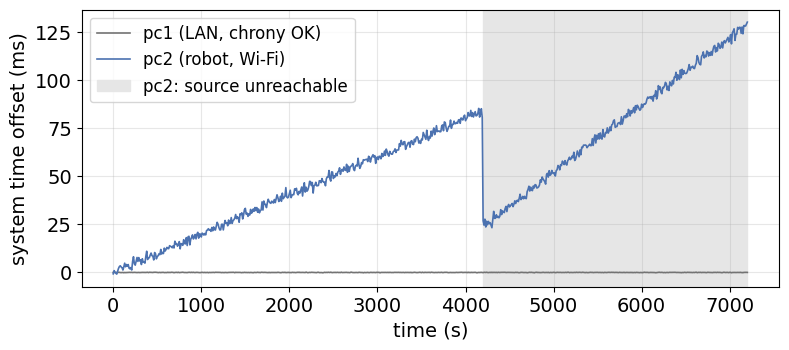

In [17]:
# セル 2-1（発展）: chrony ログを読む・描く
pc1 = pd.read_csv(DATA_DIR / "chrony_pc1.csv")
pc2 = pd.read_csv(DATA_DIR / "chrony_pc2.csv")
print(pc2.head(3).to_string())
print("\npc2 の source の内訳:", pc2.source.value_counts().to_dict())

fig, ax = plt.subplots()
ax.plot(
    pc1.t_s,
    pc1.system_time_offset_s * 1e3,
    color=GRAY,
    lw=1.2,
    label="pc1 (LAN, chrony OK)",
)
ax.plot(
    pc2.t_s,
    pc2.system_time_offset_s * 1e3,
    color=ACCENT,
    lw=1.2,
    label="pc2 (robot, Wi-Fi)",
)
lost = pc2.loc[pc2.source == "unreachable", "t_s"]
if not lost.empty:
    ax.axvspan(lost.min(), pc2.t_s.max(), color="0.9", label="pc2: source unreachable")
ax.set_xlabel("time (s)")
ax.set_ylabel("system time offset (ms)")
ax.legend(loc="upper left")
plt.show()

In [18]:
# セル 2-2【TODO-4】（発展）: 直線当てはめでドリフト (ppm) を推定し、同期が外れた時刻を特定する
def fit_drift_ppm(t_s: pd.Series, offset_s: pd.Series) -> float:
    """offset_s ≈ a * t_s + b を最小二乗で当てはめ、傾き a を ppm（1e6 倍）で返す"""
    # ---- TODO-4 ここから (2 行): np.polyfit(x, y, 1) の傾きを ppm に直して返す
    slope, _ = np.polyfit(t_s, offset_s, 1)
    return float(slope * 1e6)
    # ---- TODO-4 ここまで


# ---- TODO-4 続き (1 行): 同期が外れた時刻 = source が "unreachable" になった最初の t_s
t_break = int(pc2.loc[pc2.source == "unreachable", "t_s"].min())

before = pc2[pc2.t_s < t_break]
after = pc2[pc2.t_s >= t_break]
ppm_pc1 = fit_drift_ppm(pc1.t_s, pc1.system_time_offset_s)
ppm_before = fit_drift_ppm(before.t_s, before.system_time_offset_s)
ppm_after = fit_drift_ppm(after.t_s, after.system_time_offset_s)

print(
    f"pc1                     : {ppm_pc1:+7.2f} ppm   (Frequency 列 {pc1.frequency_ppm.median():+.1f} ppm を chrony が補正済み)"
)
print(
    f"pc2 同期あり t < {t_break} s: {ppm_before:+7.2f} ppm   (Frequency 列 {before.frequency_ppm.median():+.1f} ppm)"
)
print(
    f"pc2 同期なし t ≥ {t_break} s: {ppm_after:+7.2f} ppm   (Frequency 列 {after.frequency_ppm.median():+.1f} ppm ← 凍結。もう当てにならない)"
)
print(
    f"→ {ppm_after:.0f} ppm なら 1 日で {ppm_after * 1e-6 * 86400:.1f} 秒ずれる（S33: 20 ppm → 1.7 秒）"
)

pc1                     :   -0.00 ppm   (Frequency 列 +3.0 ppm を chrony が補正済み)
pc2 同期あり t < 4200 s:  +20.04 ppm   (Frequency 列 +20.0 ppm)
pc2 同期なし t ≥ 4200 s:  +35.02 ppm   (Frequency 列 +20.0 ppm ← 凍結。もう当てにならない)
→ 35 ppm なら 1 日で 3.0 秒ずれる（S33: 20 ppm → 1.7 秒）


In [19]:
# セル 2-6【self-check】Step 2 発展
assert abs(ppm_pc1) < 1.0, (
    f"pc1 は chrony が効いているのでドリフトはほぼ 0 のはず（{ppm_pc1:.2f} ppm）"
)
freq_before = before.frequency_ppm.median()
assert abs(ppm_before - freq_before) / abs(freq_before) < 0.2, (
    "この合成モデルでは補正不足の区間の傾きと Frequency 列を ±20% で対応させています"
)
assert ppm_after > ppm_before, (
    "同期が切れた後のほうがドリフトが大きいはず（機体が温まった）"
)
assert fp(int(round(ppm_after / 5) * 5)) == "9f14025af006", (
    f"同期後のドリフト {ppm_after:.1f} ppm が許容幅から外れています"
)
assert fp(int(round(t_break / 100) * 100)) == "be5220c4102d", (
    f"同期が外れた時刻 {t_break} s が違います"
)
print("Step 2 発展 self-check: OK（この合成モデルでの照合）")

Step 2 発展 self-check: OK（この合成モデルでの照合）


## 発展 Step 3：仮想化（発展3分）— S57, S58

実は、いま使っている Colab そのものがコンテナです。

- 3-1：`/proc/1/cgroup` と `/proc/self/ns/` で **namespace の中** にいることを見る。`hostname` と `ip addr` で net namespace を確かめる（S57, S58）
- 3-2：`/sys/fs/cgroup` の **CPU とメモリの上限** を読む。`nproc` の値と比較（一致する場合もあります）（S57 cgroups）

見えない項目は OS・権限・マウントの違いなどでも生じます。表示だけでコンテナと断定せず、実行環境と合わせて判断します。上限ファイルを読めない場合は self-check を「未確認」として残します。

In [20]:
# セル 3-1: コンテナの中から見える世界。無いものは「(見えない)」と表示する
import subprocess


def _clip(text: str, max_lines: int) -> str:
    lines = text.strip().splitlines()
    tail = f"\n... ({len(lines) - max_lines} 行省略)" if len(lines) > max_lines else ""
    return "\n".join(lines[:max_lines]) + tail


def sh(cmd: str, max_lines: int = 12) -> str:
    """シェルコマンドを実行して出力を返す。失敗しても止まらない"""
    try:
        out = subprocess.run(
            cmd, shell=True, capture_output=True, text=True, timeout=10, check=False
        )
    except (OSError, subprocess.SubprocessError) as e:
        return f"(見えない: {type(e).__name__})"
    if out.returncode != 0 and not out.stdout.strip():
        return f"(見えない: exit {out.returncode} {out.stderr.strip()[:80]})"
    return _clip(out.stdout, max_lines)


def cat(path: str, max_lines: int = 12) -> str:
    """ファイルを読んで返す。読めなければ「(見えない)」"""
    try:
        return _clip(Path(path).read_text(), max_lines)
    except OSError as e:
        return f"(見えない: {type(e).__name__})"


for title, out in [
    (
        "cat /proc/1/cgroup   (PID 1 から見える cgroup。表示だけで隔離を断定しない)",
        cat("/proc/1/cgroup"),
    ),
    ("cat /proc/1/comm     (見えている PID 1 のコマンド)", cat("/proc/1/comm")),
    (
        "ls -l /proc/self/ns/ (この process の namespace。番号がホストと違えば別世界)",
        sh("ls -l /proc/self/ns/"),
    ),
    (
        "hostname / cat /etc/hostname   (uts namespace)",
        sh("hostname") + "\n" + cat("/etc/hostname"),
    ),
    (
        "ip -brief addr       (見えているネットワークのインタフェース)",
        sh("ip -brief addr 2>/dev/null || cat /proc/net/dev"),
    ),
    ("nproc                (この process から見えるコア数)", sh("nproc")),
]:
    print(f"$ {title}\n{out}\n")

$ cat /proc/1/cgroup   (PID 1 から見える cgroup。表示だけで隔離を断定しない)
0::/

$ cat /proc/1/comm     (見えている PID 1 のコマンド)
docker-init

$ ls -l /proc/self/ns/ (この process の namespace。番号がホストと違えば別世界)
total 0
lrwxrwxrwx 1 root root 0 Sep 16 04:46 cgroup -> cgroup:[4026532421]
lrwxrwxrwx 1 root root 0 Sep 16 04:46 ipc -> ipc:[4026532419]
lrwxrwxrwx 1 root root 0 Sep 16 04:46 mnt -> mnt:[4026532417]
lrwxrwxrwx 1 root root 0 Sep 16 04:46 net -> net:[4026532422]
lrwxrwxrwx 1 root root 0 Sep 16 04:46 pid -> pid:[4026532420]
lrwxrwxrwx 1 root root 0 Sep 16 04:46 pid_for_children -> pid:[4026532420]
lrwxrwxrwx 1 root root 0 Sep 16 04:46 time -> time:[4026531834]
lrwxrwxrwx 1 root root 0 Sep 16 04:46 time_for_children -> time:[4026531834]
lrwxrwxrwx 1 root root 0 Sep 16 04:46 user -> user:[4026531837]
lrwxrwxrwx 1 root root 0 Sep 16 04:46 uts -> uts:[4026532418]

$ hostname / cat /etc/hostname   (uts namespace)
0cbc08803c63
0cbc08803c63

$ ip -brief addr       (見えているネットワークのインタフェース)
lo               UNKNOWN      

In [21]:
# セル 3-2【TODO-7】: cgroup の CPU とメモリの上限を読む（S57 cgroups）
def read_first(paths: list[str]) -> tuple[str | None, str | None]:
    """候補のうち最初に読めたファイルの (path, 中身) を返す。どれも読めなければ (None, None)"""
    for p in paths:
        try:
            return p, Path(p).read_text().strip()
        except OSError:
            continue
    return None, None


# 自分の cgroup パス（cgroup v2 なら "0::/path" の path 部分。コンテナの中では普通 "/"）
own_cgroup = cat("/proc/self/cgroup").splitlines()[0].split(":")[-1]
MEM_CANDIDATES = [
    f"/sys/fs/cgroup{own_cgroup}/memory.max",
    "/sys/fs/cgroup/memory.max",
    "/sys/fs/cgroup/memory/memory.limit_in_bytes",  # cgroup v1
]
CPU_CANDIDATES = [
    f"/sys/fs/cgroup{own_cgroup}/cpu.max",
    "/sys/fs/cgroup/cpu.max",
    "/sys/fs/cgroup/cpu/cpu.cfs_quota_us",  # cgroup v1
]
mem_path, mem_raw = read_first(MEM_CANDIDATES)
cpu_path, cpu_raw = read_first(CPU_CANDIDATES)
print(f"memory: {mem_path} -> {mem_raw!r}")
print(f"cpu:    {cpu_path} -> {cpu_raw!r}")

# ---- TODO-7 ここから (4〜6 行):
#   mem_limit_bytes: mem_raw が None か "max"（上限なし）なら None、数値なら int
#   cpu_limit:       cpu.max は "quota period" の 2 語。quota が "max" なら None、数値なら quota / period（使えるコア数）
#                    v1 の cfs_quota_us は 1 語で -1 が上限なし（period は 100000 とみなす）
mem_limit_bytes = None if mem_raw in (None, "max") else int(mem_raw)
if cpu_raw is None:
    cpu_limit = None
else:
    quota, *rest = cpu_raw.split()
    period = int(rest[0]) if rest else 100_000
    cpu_limit = None if quota in ("max", "-1") else int(quota) / period
# ---- TODO-7 ここまで

mem_match = re.search(r"MemTotal:\s+(\d+)", cat("/proc/meminfo"))
mem_total_kb = int(mem_match.group(1)) if mem_match else None
mem_txt = (
    "読めない"
    if mem_raw is None
    else (
        "上限なし" if mem_limit_bytes is None else f"{mem_limit_bytes / 2**30:.1f} GiB"
    )
)
cpu_txt = (
    "読めない"
    if cpu_raw is None
    else ("上限なし" if cpu_limit is None else f"{cpu_limit:.2f} コア")
)
print(f"\nメモリ上限: {mem_txt}   (/proc/meminfo の MemTotal は {mem_total_kb} KiB)")
print(f"CPU 上限:   {cpu_txt}   (nproc は {sh('nproc')})")

memory: /sys/fs/cgroup/memory.max -> 'max'
cpu:    /sys/fs/cgroup/cpu.max -> 'max 100000'

メモリ上限: 上限なし   (/proc/meminfo の MemTotal は 13286944 KiB)
CPU 上限:   上限なし   (nproc は 2)


In [22]:
# セル 3-3【self-check】Step 3
if mem_raw is None or cpu_raw is None:
    print(
        "Step 3 未確認: この環境では上限ファイルを読めません。Colabで候補パスを確認してください。"
    )
else:
    assert mem_limit_bytes is None or mem_limit_bytes > 0
    assert cpu_limit is None or cpu_limit > 0
    print(
        "Step 3 self-check: OK（読めた上限の形式を確認。ホスト全体との比較は別途必要）"
    )

Step 3 self-check: OK（読めた上限の形式を確認。ホスト全体との比較は別途必要）


## 発展 Step 4：デバイス（発展3分）— S73, S74

- 発展4-1：`/proc/cpuinfo`、`/proc/meminfo`、`lspci`、`ls -l /dev` で Colab から見えるデバイスを列挙する。見えないものが多い（S73：c / b、メジャー・マイナー番号）
- 発展4-2・4-3：`udevadm info -a -n /dev/ttyUSB0` の出力からシリアル番号を読み、**固定名を付ける udev ルール** を書く（S74）。Colab では当てられないので正規表現で文法チェックだけします

In [23]:
# セル 4-2【TODO-8】: udevadm info の出力から idVendor / idProduct / serial を読む
udev_txt = (DATA_DIR / "udevadm_info_ttyUSB0.txt").read_text()
print(udev_txt[:1900], "\n...")

# ---- TODO-8 ここから (3 行): 正規表現で 3 つの属性を取り出す（最初に出てくるのが一番近い親 = FTDI チップ本体）
#   例: re.search(r'ATTRS\{idVendor\}=="([0-9a-f]+)"', udev_txt).group(1)
id_vendor = re.search(r'ATTRS\{idVendor\}=="([0-9a-f]+)"', udev_txt).group(1)
id_product = re.search(r'ATTRS\{idProduct\}=="([0-9a-f]+)"', udev_txt).group(1)
serial = re.search(r'ATTRS\{serial\}=="([^"]+)"', udev_txt).group(1)
# ---- TODO-8 ここまで
print(f"idVendor={id_vendor} idProduct={id_product} serial={serial}")

Udevadm info starts with the device specified by the devpath and then
walks up the chain of parent devices. It prints for every device
found, all possible attributes in the udev rules key format.
A rule to match, can be composed by the attributes of the device
and the attributes from one single parent device.

  looking at device '/devices/pci0000:00/0000:00:14.0/usb1/1-3/1-3.2/1-3.2:1.0/ttyUSB0/tty/ttyUSB0':
    KERNEL=="ttyUSB0"
    SUBSYSTEM=="tty"
    DRIVER==""
    ATTR{power/control}=="auto"
    ATTR{power/runtime_active_time}=="0"
    ATTR{power/runtime_status}=="unsupported"
    ATTR{power/runtime_suspended_time}=="0"

  looking at parent device '/devices/pci0000:00/0000:00:14.0/usb1/1-3/1-3.2/1-3.2:1.0/ttyUSB0':
    KERNELS=="ttyUSB0"
    SUBSYSTEMS=="usb-serial"
    DRIVERS=="ftdi_sio"
    ATTRS{event_char}=="0"
    ATTRS{latency_timer}=="16"
    ATTRS{port_number}=="0"

  looking at parent device '/devices/pci0000:00/0000:00:14.0/usb1/1-3/1-3.2/1-3.2:1.0':
    KERNELS=="1-3.

In [24]:
# セル 4-3【TODO-9】: シリアル番号で固定名を付ける udev ルールを書く（S74）
#   要件: SUBSYSTEM が tty、ATTRS{idVendor} と ATTRS{serial} で機体を特定、SYMLINK+ で /dev/robot_arm、MODE 0660、GROUP dialout
# ---- TODO-9 ここから (1〜2 行): 1 行のルール文字列を udev_rule に（f-string で id_vendor と serial を埋める）
udev_rule = (
    f'SUBSYSTEM=="tty", ATTRS{{idVendor}}=="{id_vendor}", ATTRS{{serial}}=="{serial}", '
    'SYMLINK+="robot_arm", MODE="0660", GROUP="dialout"'
)
# ---- TODO-9 ここまで
print(udev_rule)
print(
    "\n手元のロボット PC なら:\n"
    "  echo '<上のルール>' | sudo tee /etc/udev/rules.d/99-robot-arm.rules\n"
    "  sudo udevadm control --reload && sudo udevadm trigger\n"
    "  ls -l /dev/robot_arm     # → ttyUSB0 へのシンボリックリンク。番号が変わっても追いかける"
)

SUBSYSTEM=="tty", ATTRS{idVendor}=="0403", ATTRS{serial}=="FT1A2B3C", SYMLINK+="robot_arm", MODE="0660", GROUP="dialout"

手元のロボット PC なら:
  echo '<上のルール>' | sudo tee /etc/udev/rules.d/99-robot-arm.rules
  sudo udevadm control --reload && sudo udevadm trigger
  ls -l /dev/robot_arm     # → ttyUSB0 へのシンボリックリンク。番号が変わっても追いかける


In [25]:
# セル 4-4【self-check】Step 4
assert (id_vendor, id_product) == ("0403", "6001"), (
    "FTDI FT232R は idVendor 0403 / idProduct 6001"
)
assert serial == "FT1A2B3C", f"serial が違います: {serial}"
assert re.search(r'SUBSYSTEM=="tty"', udev_rule), 'SUBSYSTEM=="tty" が要る'
assert re.search(r'ATTRS\{serial\}=="FT1A2B3C"', udev_rule), (
    'ATTRS{serial}=="FT1A2B3C" が要る（ATTR ではなく ATTRS: 親デバイスの属性）'
)
assert re.search(r'SYMLINK\+="[A-Za-z0-9_./-]+"', udev_rule), 'SYMLINK+="名前" が要る'
assert "\n" not in udev_rule.strip() and udev_rule.count(",") >= 2, (
    "udev ルールは 1 行、キーはカンマ区切り"
)
print(
    "Step 4 self-check: OK（教材の属性・構文を確認。実機への適用とリンク先の確認は未実施）"
)

Step 4 self-check: OK（教材の属性・構文を確認。実機への適用とリンク先の確認は未実施）


In [26]:
# セル 4-1（発展）: Colab から見えるデバイスを列挙する
import stat

cpuinfo = cat("/proc/cpuinfo", max_lines=10**6)
cpu_models = [
    line.split(":", 1)[1].strip()
    for line in cpuinfo.splitlines()
    if line.startswith("model name")
]
print(
    f"CPU: {len(cpu_models)} 論理コア  {cpu_models[0] if cpu_models else '(見えない)'}"
)
print(cat("/proc/meminfo").splitlines()[0])
print(f"\n$ lspci\n{sh('lspci', max_lines=8)}")
print(f"\n$ nvidia-smi -L\n{sh('nvidia-smi -L', max_lines=4)}")

# /dev の中身を種類別に数える（S73: c = キャラクタ, b = ブロック, メジャー/マイナー番号）
dev = Path("/dev")
chars, blocks, others = [], [], []
for p in sorted(dev.iterdir()):
    try:
        st = p.lstat()
    except OSError:
        continue
    if stat.S_ISCHR(st.st_mode):
        chars.append((p.name, os.major(st.st_rdev), os.minor(st.st_rdev)))
    elif stat.S_ISBLK(st.st_mode):
        blocks.append((p.name, os.major(st.st_rdev), os.minor(st.st_rdev)))
    else:
        others.append(p.name)
print(
    f"\n/dev: キャラクタ {len(chars)} 個, ブロック {len(blocks)} 個, その他 {len(others)} 個（手元の PC なら数百個ある）"
)
print("キャラクタデバイス (name, major, minor):", chars[:10])
print("ブロックデバイス:", blocks[:6] or "(見えない: コンテナはディスクを直接見せない)")
for name in ["video0", "ttyUSB0", "ttyACM0", "nvidia0", "bus/usb", "sda", "nvme0n1"]:
    print(f"  /dev/{name}: {'ある' if (dev / name).exists() else '見えない'}")

CPU: 2 論理コア  Intel(R) Xeon(R) CPU @ 2.20GHz
MemTotal:       13286944 kB

$ lspci
(見えない: exit 127 /bin/sh: 1: lspci: not found)

$ nvidia-smi -L
(見えない: exit 127 /bin/sh: 1: nvidia-smi: not found)

/dev: キャラクタ 7 個, ブロック 0 個, その他 9 個（手元の PC なら数百個ある）
キャラクタデバイス (name, major, minor): [('full', 1, 7), ('fuse', 10, 229), ('null', 1, 3), ('random', 1, 8), ('tty', 5, 0), ('urandom', 1, 9), ('zero', 1, 5)]
ブロックデバイス: (見えない: コンテナはディスクを直接見せない)
  /dev/video0: 見えない
  /dev/ttyUSB0: 見えない
  /dev/ttyACM0: 見えない
  /dev/nvidia0: 見えない
  /dev/bus/usb: 見えない
  /dev/sda: 見えない
  /dev/nvme0n1: 見えない


## 発展 Step 5（発展）：プロファイルの読み取り — S19, S20, S24, S26, S27

時間が余った人向け。1 章の切り分け手順（S27）をログの上でなぞります。

- 5-1：`py-spy top` の出力から **CPU を食っている関数** を特定し、1 フレームあたりのコストを推定する（S19, S20）
- 5-2：`nvidia-smi dmon` の GPU-Util の波形と学習 step の内訳から、**データローダ律速** かどうかを判定する（S24, S26）

In [27]:
# セル 5-1【TODO-10】: py-spy top の出力を読む
pyspy_txt = (DATA_DIR / "pyspy_top.txt").read_text()
print(pyspy_txt)

# ---- TODO-10 ここから (3 行): 各行の %Own, OwnTime, 関数名, ファイル名を取り出し、%Own が最大の関数を top_function に
#   行の形:  " 38.00%   38.00%   45.60s    45.60s   depth_to_pointcloud (depth_proc/pointcloud.py)"
#   ヒント: re.findall(r"^\s*([\d.]+)%\s+[\d.]+%\s+([\d.]+)s\s+[\d.]+s\s+(\S+) \((\S+)\)", pyspy_txt, flags=re.M)
rows = re.findall(
    r"^\s*([\d.]+)%\s+[\d.]+%\s+([\d.]+)s\s+[\d.]+s\s+(\S+) \((\S+)\)",
    pyspy_txt,
    flags=re.M,
)
prof = pd.DataFrame(rows, columns=["own_pct", "own_s", "function", "file"]).astype(
    {"own_pct": float, "own_s": float}
)
top_function = prof.loc[prof.own_pct.idxmax(), "function"]
# ---- TODO-10 ここまで
print(prof.head(5).to_string(index=False))

# 1 フレームあたりのコスト = OwnTime ÷ 処理したフレーム数（末尾の ros2 topic hz × 計測時間）
DURATION_S = 120
points_hz = float(re.search(r"average rate: ([\d.]+)", pyspy_txt).group(1))
active = float(re.search(r"Active: ([\d.]+)%", pyspy_txt).group(1)) / 100
n_frames = points_hz * DURATION_S
own_s_top = float(prof.loc[prof.function == top_function, "own_s"].iloc[0])
per_frame_ms = own_s_top / n_frames * 1e3
print(
    f"\n最重関数 {top_function}: {own_s_top:.1f} s / {n_frames:.0f} フレーム = {per_frame_ms:.1f} ms/フレーム"
)
print(
    f"プロセス全体では 1 フレーム {DURATION_S * active / n_frames * 1e3:.0f} ms → 1 コアでは約 {points_hz:.0f} Hz が上限。30 Hz の depth に追いつかない（S19）"
)

# Captured with: py-spy top --pid 4242 --rate 100   (duration 120 s, one snapshot at the end)
# Process: depth_to_pointcloud_node (subscribes /cam_head/depth/image_raw, publishes /cam_head/points)

Total Samples 12000
GIL: 91.50%, Active: 98.20%, Threads: 4

  %Own   %Total  OwnTime  TotalTime  Function (filename)
 38.00%   38.00%   45.60s    45.60s   depth_to_pointcloud (depth_proc/pointcloud.py)
 27.00%   27.00%   32.40s    32.40s   png_encode (image_transport_py/png_codec.py)
 12.00%   12.00%   14.40s    14.40s   imgmsg_to_cv2 (cv_bridge/core.py)
  9.00%    9.00%   10.80s    10.80s   serialize_message (rclpy/serialization.py)
  4.50%    4.50%    5.40s     5.40s   deserialize_message (rclpy/serialization.py)
  3.00%   98.20%    3.60s   117.84s   spin_once (rclpy/executors.py)
  2.00%   95.00%    2.40s   114.00s   depth_callback (depth_proc/node.py)
  1.50%    1.50%    1.80s     1.80s   _wait_for_ready_callbacks (rclpy/executors.py)
  1.20%    1.20%    1.44s     1.44s   <listcomp> (de

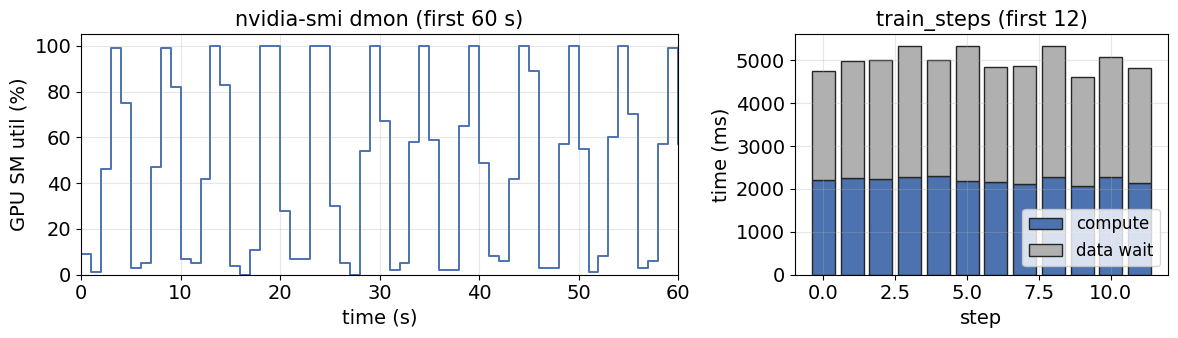

GPU-Util の波形の周期 ≈ 5 s,  step 時間の平均 = 5.06 s  → 波打ちの 1 周期 = 1 step
data_wait / step = 55%,  GPU が遊んでいる時間 = 42%  →  データローダ律速: True
対策 (S26): num_workers を増やす / 事前デコード / ローカル SSD にステージング / シャーディング。GPU を増やす前にここを直す


In [28]:
# セル 5-2【TODO-11】: GPU-Util の波形と step の内訳から、データローダ律速かを判定する（S24, S26, S27）
dmon = pd.read_csv(DATA_DIR / "nvidia_dmon.csv")
steps = pd.read_csv(DATA_DIR / "train_steps.csv")

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.6, 1.0]}
)
ax1.step(dmon.t_s, dmon.sm_util, where="post", color=ACCENT, lw=1.4)
ax1.set_xlim(0, 60)
ax1.set_ylim(0, 105)
ax1.set_xlabel("time (s)")
ax1.set_ylabel("GPU SM util (%)")
ax1.set_title("nvidia-smi dmon (first 60 s)")
k = np.arange(12)
ax2.bar(k, steps.compute_ms[:12], color=ACCENT, edgecolor="0.15", label="compute")
ax2.bar(
    k,
    steps.data_wait_ms[:12],
    bottom=steps.compute_ms[:12],
    color="#B0B0B0",
    edgecolor="0.15",
    label="data wait",
)
ax2.set_xlabel("step")
ax2.set_ylabel("time (ms)")
ax2.set_title("train_steps (first 12)")
ax2.legend(loc="lower right")
plt.tight_layout()
plt.show()


def dominant_period_s(x: np.ndarray, max_lag: int = 30) -> int:
    """自己相関が最大になるラグ（≥ 2 s）を周期として返す"""
    x = x - x.mean()
    acf = np.correlate(x, x, "full")[len(x) - 1 :] / (x @ x)
    return 2 + int(np.argmax(acf[2:max_lag]))


period_s = dominant_period_s(dmon.sm_util.to_numpy(dtype=float))
print(
    f"GPU-Util の波形の周期 ≈ {period_s} s,  step 時間の平均 = {steps.step_time_ms.mean() / 1e3:.2f} s  → 波打ちの 1 周期 = 1 step"
)

# ---- TODO-11 ここから (3 行):
#   data_wait_frac: step 時間に占める data_wait の割合の平均
#   low_util_frac:  sm_util < 20 のサンプルの割合（GPU が遊んでいる時間の割合）
#   dataloader_bound: 両方とも 0.3 を超えていれば True
data_wait_frac = float((steps.data_wait_ms / steps.step_time_ms).mean())
low_util_frac = float((dmon.sm_util < 20).mean())
dataloader_bound = bool(data_wait_frac > 0.3 and low_util_frac > 0.3)
# ---- TODO-11 ここまで
print(
    f"data_wait / step = {data_wait_frac:.0%},  GPU が遊んでいる時間 = {low_util_frac:.0%}  →  データローダ律速: {dataloader_bound}"
)
print(
    "対策 (S26): num_workers を増やす / 事前デコード / ローカル SSD にステージング / シャーディング。GPU を増やす前にここを直す"
)

In [29]:
# セル 5-3【self-check】Step 5
assert fp(top_function) == "6b4b590e5d7e", f"最重関数が違います: {top_function}"
assert fp(int(round(per_frame_ms / 10) * 10)) == "624b60c58c9d", (
    f"1 フレームあたりのコスト {per_frame_ms:.1f} ms が許容幅から外れています"
)
step_mean_s = steps.step_time_ms.mean() / 1e3
assert abs(period_s - step_mean_s) / step_mean_s < 0.2, (
    "GPU-Util の周期は step 時間と ±20% で一致するはず"
)
assert 0.0 <= data_wait_frac <= 1.0 and 0.0 <= low_util_frac <= 1.0
assert fp(bool(dataloader_bound)) == "3cbc87c7681f", "判定が真値と一致しません"
print(
    f"Step 5 self-check: OK  ({top_function} が {per_frame_ms:.0f} ms/フレーム, データローダ律速 = {dataloader_bound})"
)

Step 5 self-check: OK  (depth_to_pointcloud が 32 ms/フレーム, データローダ律速 = True)


## まとめ、さらに遊びたい人へ（S100）

発展で確認したもの：コピーの実測時間、帯域の試算と模擬ログ、cgroup の上限、udev の固定名。時計の回帰やページキャッシュは発展です。

**実データの検査へつなぐ（発展）**

基礎編第6回 p57–58 の「可視化と統計的チェック」も使い、次を組み合わせてください。

- **目視**：グリッパが閉じる映像の瞬間と、閉指令の立ち上がりを比べる。
- **統計**：タイムスタンプ差分 Δt の分布を調べ、欠落や間隔の揺れの候補を探す。
- **切り分け**：時刻印の意味、時計のずれ、帯域、CPUの飽和のうち、次にどれを測るか決める。

この演習の配布データは模擬ログで、映像・指令のペアは含みません。目視確認は実データを使う際の発展課題です。
第2回のチャレンジ3に戻り、自動checkにできる項目、目視が必要な項目、FAILの基準を書いてみましょう。

参考：第2回「PushTで学ぶRoboOps入門」§3・チャレンジ3、基礎編第6回 `PAI_lecture6_v4.pdf` p57–58。

手元にロボット PC がある人は、同じコマンドを実機で：

- `chronyc tracking` / `chronyc sources -v`：時計は誰を見て、どれだけずれているか
- `lsusb -t`：USB の木と各ポートの速度（480M / 5000M）
- `udevadm info -a -n /dev/ttyUSB0`：今日書いたルールを当ててみる
- `docker run --network host --ipc=host ...`：Linux実機で、netとipcの区画が原因かを個別に確認する際の設定例
- `cyclictest`（`rt-tests`）：リアルタイム性のジッタ
- `py-spy top --pid <PID>`、`nvidia-smi dmon`、`ros2 topic hz` / `ros2 topic bw`：Step 5 の道具

観測した値と原因候補を対応づけ、次に確かめる項目を一つ決めてください。

## 参考文献・データの出典

[7] chrony project. chronyc manual.

https://chrony-project.org/doc/4.8/chronyc.html

[11] Docker. Resource constraints / host networking / port publishing / runtime privileges.

https://docs.docker.com/engine/containers/resource_constraints/

https://docs.docker.com/engine/network/drivers/host/

https://docs.docker.com/engine/network/port-publishing/

https://docs.docker.com/engine/containers/run/#runtime-privilege-and-linux-capabilities

[14] Linux Kernel. Memory concepts / sysctl vm；udev(7).

https://docs.kernel.org/admin-guide/mm/concepts.html

https://docs.kernel.org/admin-guide/sysctl/vm.html

https://man7.org/linux/man-pages/man7/udev.7.html

[31] Debian Reference. §1.2.5 Permissions / §1.2.10 Device files（グループと機器アクセス）.

https://www.debian.org/doc/manuals/debian-reference/ch01.en.html

[33] 池田悠也 (2026). PushTで学ぶRoboOps入門. 第2回Notebook・Docker構成（講座配布資料／一般公開URLなし）.



[35] PyTorch 2.14. CPUスレッド数 / DataLoader.

https://docs.pytorch.org/docs/2.14/generated/torch.set_num_threads.html

https://docs.pytorch.org/docs/2.14/data.html

[36] Python threading / monotonic；NumPy copies and views；RFC 8085.

https://docs.python.org/3/library/threading.html

https://docs.python.org/3/library/time.html#time.monotonic

https://numpy.org/doc/stable/user/basics.copies.html

https://www.rfc-editor.org/rfc/rfc8085.html

[37] ROS. compressed_depth_image_transport: PNG / RVL実装（体験談の方式を補足する実装資料）.

https://github.com/ros-perception/image_transport_plugins/blob/noetic-devel/compressed_depth_image_transport/src/codec.cpp

[38] Open Robotics. tf2: Debugging problems（時刻と変換の関係。体験談はROS 1）.

https://github.com/ros2/ros2_documentation/blob/jazzy/source/Tutorials/Intermediate/Tf2/Debugging-Tf2-Problems.rst

[39] Sturm et al. (2012). A Benchmark for the Evaluation of RGB-D SLAM Systems. IROS. TUM RGB-Dデータ・形式.

https://cvg.cit.tum.de/data/datasets/rgbd-dataset

https://cvg.cit.tum.de/data/datasets/rgbd-dataset/file_formats

[40] TUM RGB-D配布元／CC BY 4.0（演習では一部を同梱・RGBを縮小）.

https://cvg.cit.tum.de/data/datasets/rgbd-dataset/download

https://creativecommons.org/licenses/by/4.0/

[41] Pillow. PNG保存オプション（compress_level）.

https://pillow.readthedocs.io/en/stable/handbook/image-file-formats.html#png

[42] Google Colab FAQ（実行環境・資源の変動）.

https://research.google.com/colaboratory/faq.html

実画像：J. Sturm, N. Engelhard, F. Endres, W. Burgard, D. Cremers (2012), IROS. CC BY 4.0。depthは原ファイルのまま24枚を選択、対応RGBは320×240へ縮小しJPEGに変換。元時刻・原ファイル名・ハッシュは同梱manifest.jsonに保存。